In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os


In [ ]:

# 统一的数据加载函数（兼容 dtype=object 的 npy 文件）
def load_scalar(path: str) -> float:
    arr = np.load(path, allow_pickle=True)
    try:
        return float(arr.item())
    except Exception:
        return float(np.asarray(arr).ravel()[0])

def load_reward(path: str) -> np.ndarray:
    arr = np.load(path, allow_pickle=True)
    if getattr(arr, 'dtype', None) == object:
        try:
            arr = np.concatenate(arr)
        except Exception:
            arr = np.array(list(arr), dtype=np.float64)
    return np.asarray(arr, dtype=np.float64).ravel()

In [ ]:
# 计算当前目录去手续费后的收益率（%）
import os
import numpy as np
import json

def _try_path(base_dir, name, use_val):
    cands = []
    if use_val:
        cands.append(os.path.join(base_dir, f"{name}_val.npy"))
    cands.append(os.path.join(base_dir, f"{name}.npy"))
    for p in cands:
        if os.path.exists(p):
            return p
    return None

def _load_scalar_or_float(path):
    arr = np.load(path)
    if hasattr(arr, "item"):
        try:
            return float(arr.item())
        except Exception:
            pass
    arr = np.array(arr).astype(float)
    return float(arr.reshape(-1)[0])

# base_dir = r'high_level\\ETHUSDT\\exp1\\seed_12345\\epoch_5\\val'  # 可改为任意 result 目录
base_dir = r'high_level\\ETHUSDT'
use_val = True

req_path = _try_path(base_dir, "require_money", use_val)
rew_path = _try_path(base_dir, "reward", use_val)
fee_path = _try_path(base_dir, "commission_fee_history", use_val)

if req_path is None or rew_path is None:
    raise FileNotFoundError(f"缺少 require_money/reward 文件于: {base_dir}")

V1 = _load_scalar_or_float(req_path)
reward = np.load(rew_path,allow_pickle=True).astype(float).flatten()
pnl_net = float(np.sum(reward))
fee_sum = 0.0
if fee_path and os.path.exists(fee_path):
    fee_arr = np.load(fee_path).astype(float).flatten()
    fee_sum = float(np.sum(fee_arr))

pnl_gross = pnl_net + fee_sum
tr_with_fee_pct = pnl_net / V1 * 100.0 if V1 != 0 else float("nan")
tr_no_fee_pct = pnl_gross / V1 * 100.0 if V1 != 0 else float("nan")

print(f"去手续费后收益率: {tr_no_fee_pct:.2f}%")
print(f"含手续费收益率: {tr_with_fee_pct:.2f}%")
print(f"手续费合计: {fee_sum:.2f}")

去手续费后收益率: 30.92%
含手续费收益率: 30.11%
手续费合计: 2.96


In [ ]:
# ...existing code...
data_dir = r'high_level\ETHUSDT\exp1\seed_12345\epoch_2\val'
V_1 = np.load(os.path.join(data_dir, 'require_money_val.npy')).item()
reward = np.load(os.path.join(data_dir, 'reward_val.npy')).flatten()
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]  # 用累计和还原最终资金
return_rate = V_T / V_1
print(f'Return Rate (final_balance / required_money): {return_rate:.4f}')
return_rate = (V_T / V_1 - 1) * 100  # 换成百分比
print(f'Return Rate (final_balance / required_money): {return_rate:.2f}%')
# ...existing code...

Return Rate (final_balance / required_money): 1.3563
Return Rate (final_balance / required_money): 35.63%


In [ ]:
# 数据文件路径
data_dir = r'high_level\ETHUSDT\exp1\seed_12345\epoch_5\val'
data_dir = os.path.join('high_level', 'ETHUSDT')
files = ['action.npy', 'reward.npy', 'commission_fee_history.npy', 'final_balance.npy', 'require_money.npy']


In [ ]:
# 计算六个金融指标
reward = load_reward(os.path.join(data_dir, 'reward.npy'))
V_T = load_scalar(os.path.join(data_dir, 'final_balance.npy'))
V_1 = load_scalar(os.path.join(data_dir, 'require_money.npy'))
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1

# 2. 年度波动率 AVOL
AVOL = np.std(reward) * np.sqrt(m)

# 3. 最大回撤 MDD
cum_returns = np.cumsum(reward)
peak = np.maximum.accumulate(cum_returns)
drawdown = peak - cum_returns
MDD = np.max(drawdown)

# 4. 年化夏普比率 ASR
ASR = np.mean(reward) / np.std(reward) * np.sqrt(m)

# 5. 年化卡玛比率 ACR
ACR = np.mean(drawdown) * m

# 6. 年度索提诺比率 ASoR
downside = reward[reward < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(downside) * np.sqrt(m) if DD > 0 else 0

print(f'Total Return (TR): {TR:.4f}')
print(f'Annual Volatility (AVOL): {AVOL:.4f}')
print(f'Maximum Drawdown (MDD): {MDD:.4f}')
print(f'Annual Sharpe Ratio (ASR): {ASR:.4f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.4f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.4f}')

Total Return (TR): -0.6989
Annual Volatility (AVOL): 79.4666
Maximum Drawdown (MDD): 43.4749
Annual Sharpe Ratio (ASR): 3.3229
Annual Calmar Ratio (ACR): 6024056.9073
Annual Sortino Ratio (ASoR): -80.5723


In [ ]:
# 用 reward 和初始资金还原净值曲线，并计算六个金融指标（百分比输出）
V_1 = load_scalar(os.path.join(data_dir, 'require_money.npy'))
reward = load_reward(os.path.join(data_dir, 'reward.npy'))
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1 * 100

# 2. 年度波动率 AVOL
r = np.diff(net_value) / net_value[:-1]  # 每步收益率
AVOL = np.std(r) * np.sqrt(m) * 100

# 3. 最大回撤 MDD
peak = np.maximum.accumulate(net_value)
drawdown = (peak - net_value) / peak
MDD = np.max(drawdown) * 100

# 4. 年化夏普比率 ASR
ASR = np.mean(r) / np.std(r) * np.sqrt(m)

# 5. 年化卡玛比率 ACR
ACR = (np.mean(r) * m) / (MDD/100) if MDD > 0 else np.nan

# 6. 年度索提诺比率 ASoR
downside = r[r < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(r) / DD * np.sqrt(m) if DD > 0 else np.nan

print(f'Total Return (TR): {TR:.2f}%')
print(f'Annual Volatility (AVOL): {AVOL:.2f}%')
print(f'Maximum Drawdown (MDD): {MDD:.2f}%')
print(f'Annual Sharpe Ratio (ASR): {ASR:.2f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.2f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.2f}')

Total Return (TR): 30.11%
Annual Volatility (AVOL): 19.75%
Maximum Drawdown (MDD): 11.01%
Annual Sharpe Ratio (ASR): 3.28
Annual Calmar Ratio (ACR): 5.89
Annual Sortino Ratio (ASoR): 2.39


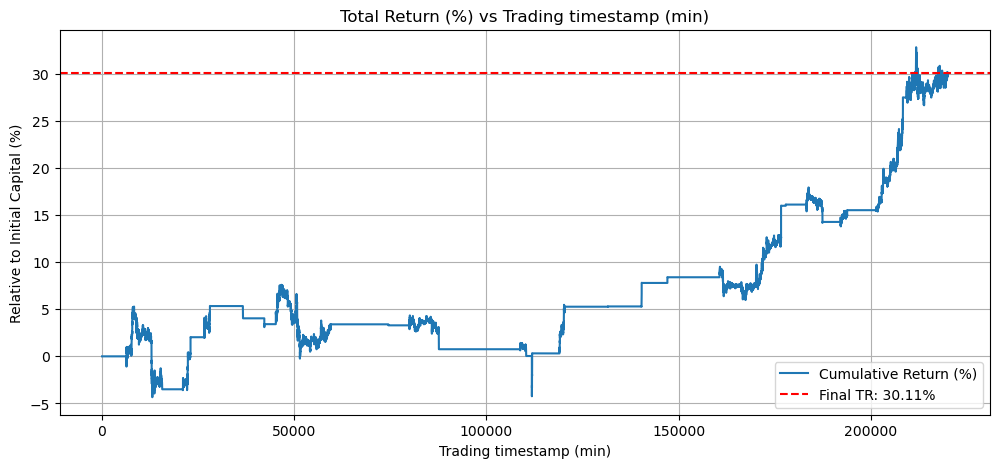

In [ ]:
# 可视化累计收益率（资金曲线）并标注最终TR值，y轴改为“Relative to Initial Capital (%)”
V_1 = load_scalar(os.path.join(data_dir, 'require_money.npy'))
reward = load_reward(os.path.join(data_dir, 'reward.npy'))
cum_return = (np.cumsum(reward)) / V_1 * 100  # 累计收益率百分比
final_tr = cum_return[-1]
timestamps = range(len(cum_return))
plt.figure(figsize=(12, 5))
plt.plot(timestamps, cum_return, label='Cumulative Return (%)')
plt.axhline(final_tr, color='r', linestyle='--', label=f'Final TR: {final_tr:.2f}%')
plt.title('Total Return (%) vs Trading timestamp (min)')
plt.xlabel('Trading timestamp (min)')
plt.ylabel('Relative to Initial Capital (%)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
# 数据文件路径
data_dir = r'high_level\ETHUSDT\exp1\seed_12345\epoch_5\val'
# data_dir = os.path.join('high_level', 'ETHUSDT')
files = ['action.npy', 'reward.npy', 'commission_fee_history.npy', 'final_balance.npy', 'require_money.npy']

# 统一的数据加载函数（兼容 dtype=object 的 npy 文件）
def load_scalar(path: str) -> float:
    arr = np.load(path, allow_pickle=True)
    try:
        return float(arr.item())
    except Exception:
        return float(np.asarray(arr).ravel()[0])

def load_reward(path: str) -> np.ndarray:
    arr = np.load(path, allow_pickle=True)
    if getattr(arr, 'dtype', None) == object:
        try:
            arr = np.concatenate(arr)
        except Exception:
            arr = np.array(list(arr), dtype=np.float64)
    return np.asarray(arr, dtype=np.float64).ravel()

In [ ]:
# 用 reward 和初始资金还原净值曲线，并计算六个金融指标（百分比输出）
V_1 = load_scalar(os.path.join(data_dir, 'require_money_val.npy'))
reward = load_reward(os.path.join(data_dir, 'reward_val.npy'))
net_value = V_1 + np.cumsum(reward)
V_T = net_value[-1]
m = 525600  # 一年分钟数

# 1. 总回报率 TR
TR = (V_T - V_1) / V_1 * 100

# 2. 年度波动率 AVOL
r = np.diff(net_value) / net_value[:-1]  # 每步收益率
AVOL = np.std(r) * np.sqrt(m) * 100

# 3. 最大回撤 MDD
peak = np.maximum.accumulate(net_value)
drawdown = (peak - net_value) / peak
MDD = np.max(drawdown) * 100

# 4. 年化夏普比率 ASR
ASR = np.mean(r) / np.std(r) * np.sqrt(m)

# 5. 年化卡玛比率 ACR
ACR = (np.mean(r) * m) / (MDD/100) if MDD > 0 else np.nan

# 6. 年度索提诺比率 ASoR
downside = r[r < 0]
DD = np.std(downside) if len(downside) > 0 else 0
ASoR = np.mean(r) / DD * np.sqrt(m) if DD > 0 else np.nan

print(f'Total Return (TR): {TR:.2f}%')
print(f'Annual Volatility (AVOL): {AVOL:.2f}%')
print(f'Maximum Drawdown (MDD): {MDD:.2f}%')
print(f'Annual Sharpe Ratio (ASR): {ASR:.2f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.2f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.2f}')

Total Return (TR): 26.43%
Annual Volatility (AVOL): 32.70%
Maximum Drawdown (MDD): 15.92%
Annual Sharpe Ratio (ASR): 2.35
Annual Calmar Ratio (ACR): 4.83
Annual Sortino Ratio (ASoR): 2.14


Initial Capital: 367.14
Final TR: 26.43%


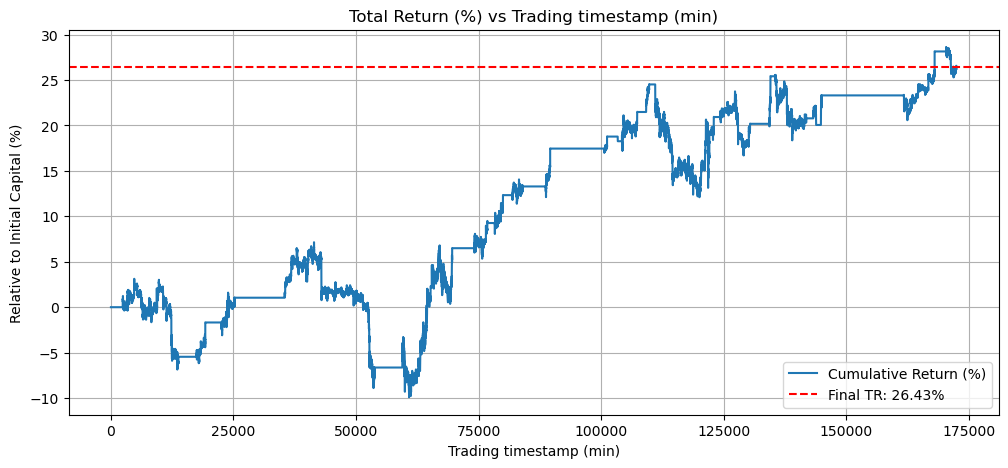

In [ ]:
# 可视化累计收益率（资金曲线）并标注最终TR值，y轴改为“Relative to Initial Capital (%)”
V_1 = load_scalar(os.path.join(data_dir, 'require_money_val.npy'))
print(f'Initial Capital: {V_1:.2f}')
reward = load_reward(os.path.join(data_dir, 'reward_val.npy'))
cum_return = (np.cumsum(reward)) / V_1 * 100  # 累计收益率百分比
final_tr = cum_return[-1]
print(f'Final TR: {final_tr:.2f}%')
timestamps = range(len(cum_return))
plt.figure(figsize=(12, 5))
plt.plot(timestamps, cum_return, label='Cumulative Return (%)')
plt.axhline(final_tr, color='r', linestyle='--', label=f'Final TR: {final_tr:.2f}%')
plt.title('Total Return (%) vs Trading timestamp (min)')
plt.xlabel('Trading timestamp (min)')
plt.ylabel('Relative to Initial Capital (%)')
plt.legend()
plt.grid(True)
plt.show()